# Regression Model

The goal of this homework is to create a regression model for predicting the car fuel efficiency (column 'fuel_efficiency_mpg').

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
# Loading the dataset

df = pd.read_csv('car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


Preparing the dataset

Use only the following columns:

'engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg'

In [57]:
columns = [
    'engine_displacement', 
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

data = df[columns]
data

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [58]:
data.dtypes

engine_displacement      int64
horsepower             float64
vehicle_weight           int64
model_year               int64
fuel_efficiency_mpg    float64
dtype: object

EDA

Look at the fuel_efficiency_mpg variable. Does it have a long tail?

In [59]:
eda = data.fuel_efficiency_mpg

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

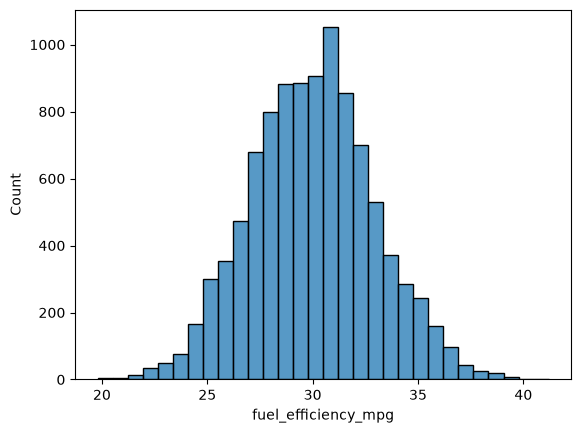

In [60]:
sns.histplot(eda, bins=30)

Question 1

There's one column with missing values. What is it?

'engine_displacement'
'horsepower'
'vehicle_weight'
'model_year'

In [61]:
# Checking for missing values in the dataset

data.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

Question 2

What's the median (50% percentile) for variable 'horsepower'?
204
254
304
354

In [62]:
data['horsepower'].median()

np.float64(254.0)

Prepare and split the dataset

Shuffle the filtered dataset and create the split exactly as in the lecture:

In [63]:
# Splitting the dataset into training, validation, and test sets
n = len(data)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

# Setting the random seed for reproducibility and shuffling the indices
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

# Creating the training, validation, and test sets using the shuffled indices
df_train = data.iloc[idx[:n_train]]
df_val = data.iloc[idx[n_train:n_train + n_val]]
df_test = data.iloc[idx[n_train + n_val:]]

In [64]:
print(len(df_train), len(df_val), len(df_test))

6000 2000 2000


Question 3

1. We need to deal with missing values for the column from Q1.
2. We have two options: fill it with 0 or with the mean of this variable.
3. Try both options. For each, train a linear regression model without regularization using the code from the lessons.
4. For computing the mean, use the training only!
5. Use the validation dataset to evaluate the models and compare the RMSE of each option.
6. Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
7. Which option gives better RMSE?

In [65]:
# Preparing the data for modeling by separating features and target variable
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

# Deleting the target variable from the feature sets
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [66]:
df_train

,engine_displacement,horsepower,vehicle_weight,model_year
6252,1900,239.0,3790,2015
4684,2000,224.0,4380,1992
1731,2330,286.0,4090,2022
4742,2300,NaN,4150,1997
4521,2340,269.0,4400,2001
...,...,...,...,...
7895,2280,242.0,4590,2018
9590,2300,NaN,4240,1984
7288,2240,255.0,4190,1989
278,2430,254.0,4280,2020


In [67]:
# Resetting the indices of the training, validation, and test sets

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [68]:
# Preparing the feature matrices X 
# filling the missing values with zeros

def prepare_X(df, fill_value=0):
    df_num = df.fillna(fill_value)
    X = df_num.values

    return X

In [75]:
# Filling with the mean value (Option 2)

horse_p = df_train['horsepower'].mean()

In [70]:
# linear regression model function

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [71]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()

    return np.sqrt(mse)

Training the model now:

In [83]:
X_train_zero = prepare_X(df_train, 0)
w0, w = train_linear_regression(X_train_zero, y_train)

X_val_zero = prepare_X(df_val, 0)
y_pred = w0 + X_val_zero.dot(w)
rmse(y_val, y_pred).round(3)

np.float64(2.205)

In [84]:
X_train_mean = prepare_X(df_train, horse_p)
w0, w = train_linear_regression(X_train_mean, y_train)

X_val_mean = prepare_X(df_val, horse_p)
y_pred = w0 + X_val_mean.dot(w)
rmse(y_val, y_pred).round(3)

np.float64(2.202)

Question 4

Now let's train a regularized linear regression.
1. For this question, fill the NAs with 0.
2. Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
3. Use RMSE to evaluate the model on the validation dataset.
4. Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
5. Which r gives the best RMSE?

If multiple options give the same best RMSE, select the smallest r.



In [85]:
# The complete regression function with regularization

def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])  # Adding regularization term 
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [86]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train_zero = prepare_X(df_train, 0)
    w0, w = train_linear_regression_reg(X_train_zero, y_train, r)

    X_val_zero = prepare_X(df_val, 0)
    y_pred = w0 + X_val_zero.dot(w)
    score = rmse(y_val, y_pred).round(4)

    print(r, w0, w, score)

0 -153.8849618823138 [-1.51505520e-03 -4.74024794e-06 -3.95418397e-03  1.02146785e-01] 2.2053
0.01 -148.3092124404723 [-0.00154178  0.00017287 -0.00396756  0.09939669] 2.2058
0.1 -111.83871039306318 [-0.0017166   0.0013346  -0.00405504  0.08140858] 2.2241
1 -32.331865964971264 [-0.0020977   0.0038672  -0.00424576  0.04219393] 2.3492
5 -7.7728522099734025 [-0.00221541  0.0046495  -0.00430467  0.03008084] 2.4094
10 -3.9871164160193766 [-0.00223356  0.00477009 -0.00431375  0.02821363] 2.4195
100 -0.40821964884790385 [-0.00225071  0.00488408 -0.00432232  0.0264484 ] 2.4292


Question 5

1. We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
2. Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
3. For each seed, do the train/validation/test split with 60%/20%/20% distribution.
4. Fill the missing values with 0 and train a model without regularization.
5. For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
6. What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
7. Round the result to 3 decimal digits (round(std, 3))

In [89]:
def score_for_seed(seed):
    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)

    df_train = data.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = data.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)

    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']

    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression(X_train, y_train)

    X_val = prepare_X(df_val, 0)
    y_pred = w0 + X_val.dot(w)
    return rmse(y_val, y_pred)

In [92]:
scores = []
for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    scores.append(score_for_seed(seed))

round(np.std(scores), 3)

np.float64(0.029)

Note: Standard deviation shows how different the values are. If it's low, then all values are approximately the same. If it's high, the values are different. If standard deviation of scores is low, then our model is stable.

In [93]:
print(len(scores))   # should be 10
print(scores)        # 10 values, all similar but not identical

10
[np.float64(2.239204143046126), np.float64(2.2021128210838845), np.float64(2.1634197787530947), np.float64(2.2043588768539224), np.float64(2.2018800943311554), np.float64(2.2457851509085134), np.float64(2.2697212079524043), np.float64(2.190794599933443), np.float64(2.216611201686444), np.float64(2.2070365928178957)]


Question 6

1. Split the dataset like previously, use seed 9.
2. Combine train and validation datasets.
3. Fill the missing values with 0 and train a model with r=0.001.
4. What's the RMSE on the test dataset?

In [94]:
def final_test_score(seed, r):
    # 1. shuffle the row positions with this seed
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    # 2. split 60/20/20
    df_train = data.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = data.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = data.iloc[idx[n_train + n_val:]].reset_index(drop=True)

    # 3. targets
    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values
    y_test = df_test['fuel_efficiency_mpg'].values

    # 4. remove the target from the features
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    # 5. combine train + validation (same order for X and y)
    df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
    y_full_train = np.concatenate([y_train, y_val])

    # 6. prepare and train with regularization
    X_full_train = prepare_X(df_full_train, 0)
    w0, w = train_linear_regression_reg(X_full_train, y_full_train, r)

    # 7. evaluate once on the test set
    X_test = prepare_X(df_test, 0)
    y_pred = w0 + X_test.dot(w)

    return rmse(y_test, y_pred)

In [95]:
round(final_test_score(9, 0.001), 3)

np.float64(2.236)